# Iris Flower Classification

## Machine Learning and Data Science Internship

**Task 1: Supervised Classification**

This project uses Logistic Regression and Decision Tree algorithms
to classify Iris flowers into three species.

In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the Iris dataset
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv"
df = pd.read_csv(url)

# Display first five rows
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [2]:
# Check dataset information
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Count each flower species
print("\nSpecies Count:")
print(df["species"].value_counts())

Dataset Shape: (150, 5)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB

Missing Values:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Species Count:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [3]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Separate input features and target
X = df.drop("species", axis=1)
y = df["species"]

# Split dataset into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Apply StandardScaler
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Display dataset sizes
print("Training data:", X_train_scaled.shape)
print("Testing data:", X_test_scaled.shape)

print("\nTraining labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training data: (120, 4)
Testing data: (30, 4)

Training labels: (120,)
Testing labels: (30,)


In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

# Create Logistic Regression model
logistic_model = LogisticRegression(max_iter=1000)

# Train Logistic Regression
logistic_model.fit(X_train_scaled, y_train)

# Create Decision Tree model
tree_model = DecisionTreeClassifier(random_state=42)

# Train Decision Tree
tree_model.fit(X_train_scaled, y_train)

print("Both models trained successfully!")


Both models trained successfully!


In [5]:
from sklearn.metrics import accuracy_score, classification_report

# Predict using Logistic Regression
y_pred_lr = logistic_model.predict(X_test_scaled)

# Predict using Decision Tree
y_pred_dt = tree_model.predict(X_test_scaled)

# Logistic Regression Evaluation
print("LOGISTIC REGRESSION RESULTS")
print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

# Decision Tree Evaluation
print("\nDECISION TREE RESULTS")
print("Accuracy:", accuracy_score(y_test, y_pred_dt))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt))

LOGISTIC REGRESSION RESULTS
Accuracy: 0.9333333333333333

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


DECISION TREE RESULTS
Accuracy: 0.9333333333333333

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



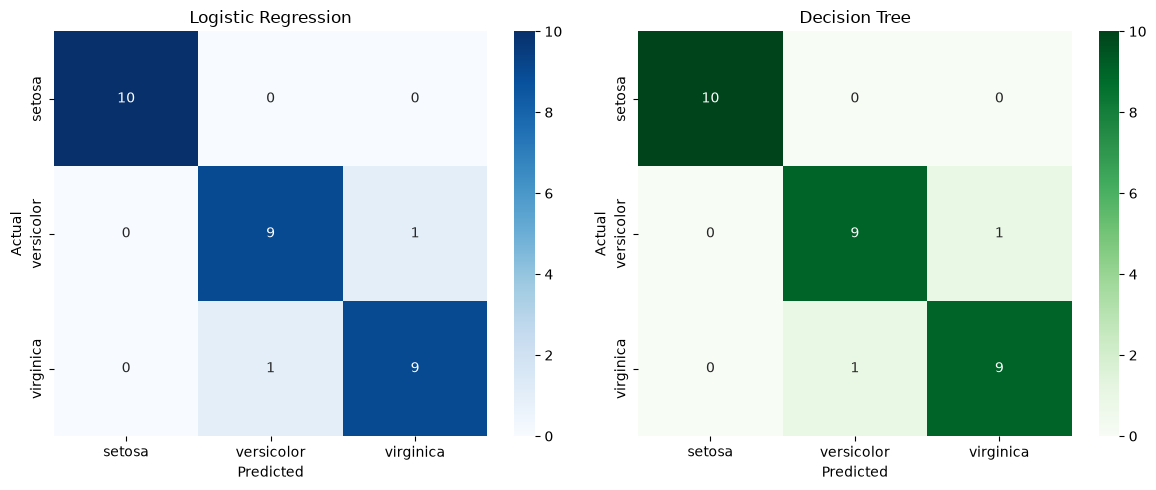

In [6]:
from sklearn.metrics import confusion_matrix

# Calculate confusion matrices
cm_lr = confusion_matrix(y_test, y_pred_lr)
cm_dt = confusion_matrix(y_test, y_pred_dt)

# Plot confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Logistic Regression
sns.heatmap(
    cm_lr, annot=True, fmt="d", cmap="Blues",
    xticklabels=logistic_model.classes_,
    yticklabels=logistic_model.classes_,
    ax=axes[0]
)
axes[0].set_title("Logistic Regression")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

# Decision Tree
sns.heatmap(
    cm_dt, annot=True, fmt="d", cmap="Greens",
    xticklabels=tree_model.classes_,
    yticklabels=tree_model.classes_,
    ax=axes[1]
)
axes[1].set_title("Decision Tree")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()


In [7]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Calculate performance metrics
results = {
    "Model": ["Logistic Regression", "Decision Tree"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_dt)
    ],
    "Precision": [
        precision_score(y_test, y_pred_lr, average="weighted"),
        precision_score(y_test, y_pred_dt, average="weighted")
    ],
    "Recall": [
        recall_score(y_test, y_pred_lr, average="weighted"),
        recall_score(y_test, y_pred_dt, average="weighted")
    ],
    "F1 Score": [
        f1_score(y_test, y_pred_lr, average="weighted"),
        f1_score(y_test, y_pred_dt, average="weighted")
    ]
}

comparison_df = pd.DataFrame(results)

# Display comparison
comparison_df


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.933333,0.933333,0.933333,0.933333
1,Decision Tree,0.933333,0.933333,0.933333,0.933333


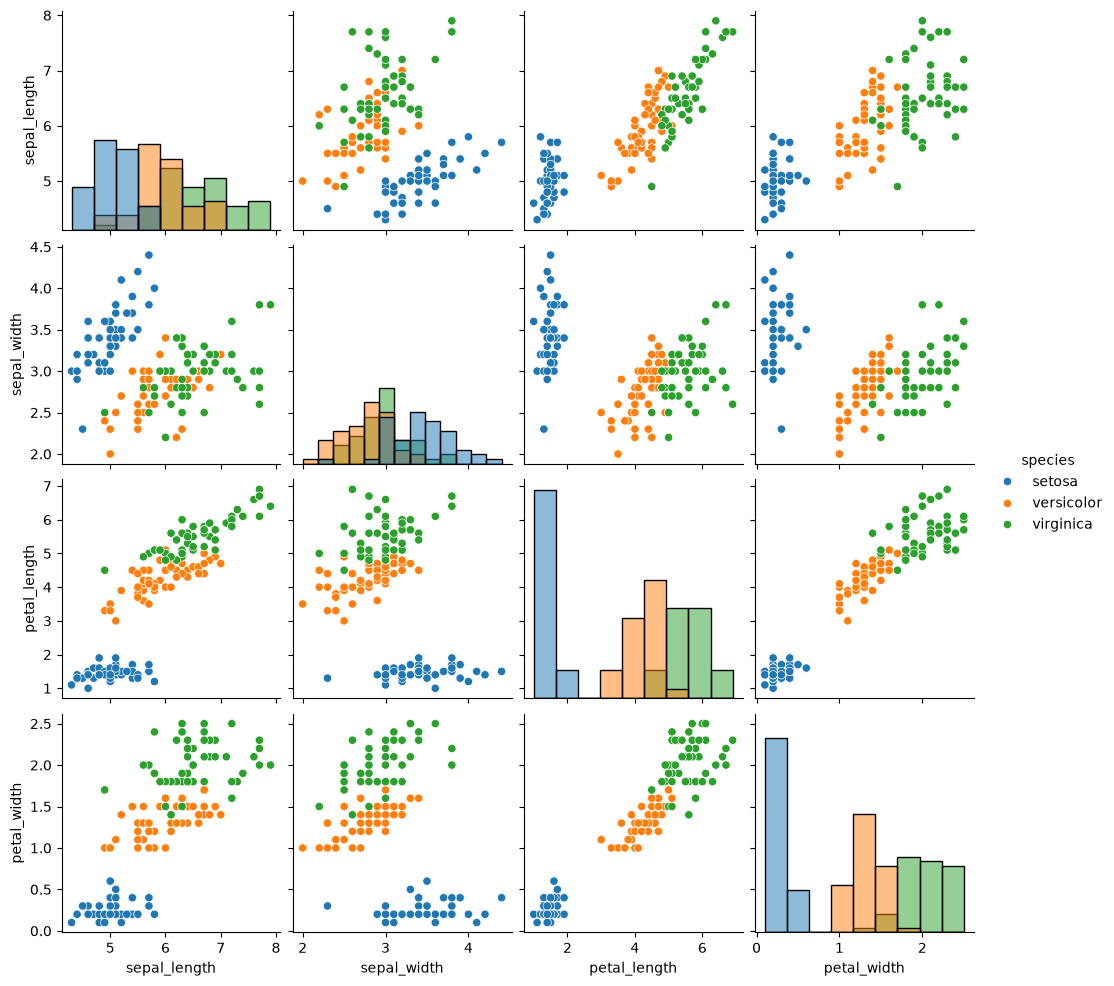

In [8]:
# Create pairplot
sns.pairplot(df, hue="species", diag_kind="hist")

# Display plot
plt.show()

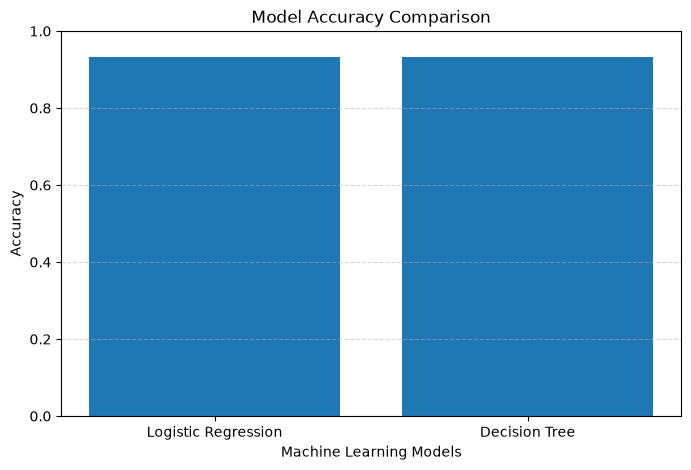

In [9]:
# Get model names and accuracy values
models = comparison_df["Model"]
accuracies = comparison_df["Accuracy"]

# Create bar chart
plt.figure(figsize=(8, 5))

plt.bar(models, accuracies)

plt.title("Model Accuracy Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy")

plt.ylim(0, 1)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.show()

In [10]:
# Save model comparison results
comparison_df.to_csv("model_comparison.csv", index=False)

print("Model comparison saved successfully!")

Model comparison saved successfully!


In [11]:
import joblib

# Save Logistic Regression model
joblib.dump(logistic_model, "logistic_regression_model.pkl")

# Save Decision Tree model
joblib.dump(tree_model, "decision_tree_model.pkl")

# Save StandardScaler
joblib.dump(scaler, "standard_scaler.pkl")

print("All models and scaler saved successfully!")

All models and scaler saved successfully!


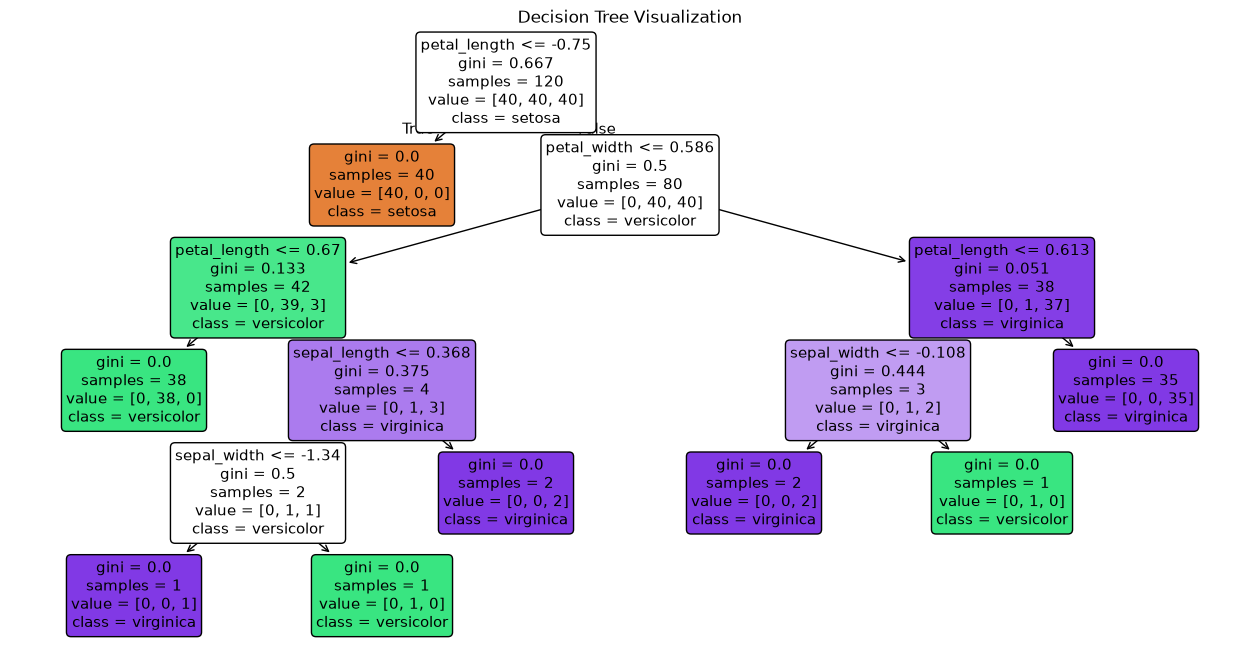

In [12]:
from sklearn.tree import plot_tree

plt.figure(figsize=(16, 8))

plot_tree(
    tree_model,
    feature_names=X.columns,
    class_names=tree_model.classes_,
    filled=True,
    rounded=True
)

plt.title("Decision Tree Visualization")
plt.show()